# Proyecto 3 — Complemento de mediciones (Colab, GPU T4)
**CC3069 · UVG · Semestre II 2026** · Integrantes: Roberto Nájera, Genser Catalán, Estuardo Castro

Este notebook completa tres mediciones que quedaron pendientes o inválidas en `proyecto3_cuda.ipynb`:

| Parte | Problema en la corrida principal | Qué hace aquí |
|---|---|---|
| **A. Kernels CUDA propios** | Numba falló con `nvJitLink … may need newer version` (incompatibilidad entre el nvJitLink de TensorFlow, CUDA 12.5, y el NVVM de Numba) | Actualiza `nvidia-nvjitlink-cu12` **antes** de importar nada y reintenta con Numba; además corre los mismos kernels en **CUDA C vía CuPy/NVRTC** (no usa nvJitLink) como comprobación cruzada |
| **B. Transferencia CPU↔GPU** | La medición dio 605 GB/s (imposible: PCIe de la T4 ≈ 12 GB/s); `tf.identity` no copió realmente | Mide la copia con CuPy y sincronización explícita, memoria paginada vs. *pinned* |
| **C. Convergencia en GPU** | Con 4 épocas fijas el modelo no converge (acc ≈ 69-72 %; la variante bs=128+fp16 quedó en 21 %) | Entrena hasta converger (como el Lab 3: máx. 15 épocas con `EarlyStopping`) para comprobar que el GPU llega a la misma exactitud, y separa el efecto del *batch size* del de la precisión mixta |

**Uso:** entorno de ejecución GPU (T4) → *Ejecutar todo* **en un entorno recién iniciado** (la celda 1 instala una librería que tiene que cargarse antes que TensorFlow). Al final se descarga `resultados_complemento.zip`; descomprímalo en `results/` del repo.

## 0. Preparación

In [1]:
# Debe correr ANTES de importar numba/cupy/tensorflow en este entorno.
!pip install -q -U nvidia-nvjitlink-cu12 kagglehub tabulate

In [2]:
import os, sys, time, subprocess, zipfile, shutil, random
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

SEED = 42
RES = Path("results"); RES.mkdir(exist_ok=True)
print(subprocess.run("nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv", shell=True, capture_output=True, text=True).stdout)
import importlib.metadata as md_
for p in ["numba", "numba-cuda", "cupy-cuda12x", "nvidia-nvjitlink-cu12", "nvidia-cuda-nvrtc-cu12"]:
    try: print(f"{p:26s}", md_.version(p))
    except Exception: print(f"{p:26s} (no instalado)")

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07

numba                      0.64.0
numba-cuda                 0.28.2
cupy-cuda12x               (no instalado)
nvidia-nvjitlink-cu12      12.9.86
nvidia-cuda-nvrtc-cu12     12.9.86


## A. Kernels CUDA propios — `Dense 4608→256 + ReLU`
Mapeo explícito: **hilo (tx,ty)** → una neurona de salida de una muestra; **bloque** 16×16 → un *tile* de 16 muestras × 16 neuronas; **grid** `⌈256/16⌉ × ⌈M/16⌉` cubre la matriz de salida. La versión *tiled* usa memoria compartida para reutilizar 16 veces cada dato cargado.
Se implementa dos veces: en **Numba** (CUDA Python) y en **CUDA C** compilado con NVRTC desde CuPy. Se valida contra NumPy y se compara con cuBLAS.

In [3]:
M, K, N = 3045, 4608, 256          # test set × (6·6·128) → 256, como en la CNN 2
TPB = 16
rng = np.random.default_rng(SEED)
Xh = rng.standard_normal((M, K), dtype=np.float32)
Wh = (rng.standard_normal((K, N), dtype=np.float32) * 0.02).astype(np.float32)
bh = (rng.standard_normal(N, dtype=np.float32) * 0.1).astype(np.float32)

t0 = time.perf_counter(); ref = np.maximum(Xh @ Wh + bh, 0); t_np = time.perf_counter() - t0
grid  = ((N + TPB - 1) // TPB, (M + TPB - 1) // TPB)      # (x = neuronas, y = muestras)
block = (TPB, TPB)
print(f"block={block} ({TPB*TPB} hilos/bloque) · grid={grid} → {grid[0]*grid[1]} bloques · {grid[0]*grid[1]*TPB*TPB:,} hilos")
rows = [{"implementacion": "NumPy (CPU, 1 hilo BLAS compartido)", "backend": "CPU", "ms": t_np * 1e3, "correcto": True}]

def timeit(launch, sync, reps=20):
    launch(); sync()                         # compila + calienta
    t0 = time.perf_counter()
    for _ in range(reps): launch()
    sync(); return (time.perf_counter() - t0) / reps

block=(16, 16) (256 hilos/bloque) · grid=(16, 191) → 3056 bloques · 782,336 hilos


In [4]:
# ---------------- A.1  Numba (CUDA Python) ----------------
try:
    from numba import cuda, float32
    import numba

    @cuda.jit
    def dense_relu_naive(X, W, b, Y):
        col = cuda.blockIdx.x * cuda.blockDim.x + cuda.threadIdx.x
        row = cuda.blockIdx.y * cuda.blockDim.y + cuda.threadIdx.y
        if row < Y.shape[0] and col < Y.shape[1]:
            acc = 0.0
            for k in range(X.shape[1]):
                acc += X[row, k] * W[k, col]
            acc += b[col]
            Y[row, col] = acc if acc > 0.0 else 0.0

    @cuda.jit
    def dense_relu_tiled(X, W, b, Y):
        sX = cuda.shared.array((TPB, TPB), float32)
        sW = cuda.shared.array((TPB, TPB), float32)
        tx, ty = cuda.threadIdx.x, cuda.threadIdx.y
        col = cuda.blockIdx.x * TPB + tx
        row = cuda.blockIdx.y * TPB + ty
        Mm, Kk, Nn = Y.shape[0], X.shape[1], Y.shape[1]
        acc = 0.0
        for t in range((Kk + TPB - 1) // TPB):
            k0 = t * TPB
            sX[ty, tx] = X[row, k0 + tx] if (row < Mm and k0 + tx < Kk) else 0.0
            sW[ty, tx] = W[k0 + ty, col] if (k0 + ty < Kk and col < Nn) else 0.0
            cuda.syncthreads()
            for j in range(TPB):
                acc += sX[ty, j] * sW[j, tx]
            cuda.syncthreads()
        if row < Mm and col < Nn:
            v = acc + b[col]
            Y[row, col] = v if v > 0.0 else 0.0

    dX, dW, db = cuda.to_device(Xh), cuda.to_device(Wh), cuda.to_device(bh)
    dY = cuda.device_array((M, N), dtype=np.float32)
    for name, kern in [("Numba naive", dense_relu_naive), ("Numba tiled (memoria compartida)", dense_relu_tiled)]:
        ms = timeit(lambda: kern[grid, block](dX, dW, db, dY), cuda.synchronize) * 1e3
        ok = bool(np.allclose(dY.copy_to_host(), ref, atol=1e-2, rtol=1e-3))
        rows.append({"implementacion": name, "backend": "Numba", "ms": ms, "correcto": ok})
        print(f"{name:34s}: {ms:8.3f} ms · correcto vs NumPy: {ok}")
except Exception as e:
    print("⚠️ Numba no pudo ejecutar los kernels:", type(e).__name__, str(e)[:300])
    print("   (se documenta en el informe; la parte A.2 reproduce los mismos kernels en CUDA C)")

Numba naive                       :   71.794 ms · correcto vs NumPy: True
Numba tiled (memoria compartida)  :   72.288 ms · correcto vs NumPy: True


In [5]:
# ---------------- A.2  CUDA C con CuPy RawKernel (NVRTC, no usa nvJitLink) ----------------
import cupy as cp
src = r"""
#define TPB 16
extern "C" __global__ void dense_relu_naive(const float* X, const float* W, const float* b, float* Y, int M, int K, int N){
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    if (row < M && col < N) {
        float acc = 0.f;
        for (int k = 0; k < K; ++k) acc += X[row*K + k] * W[k*N + col];
        acc += b[col];
        Y[row*N + col] = acc > 0.f ? acc : 0.f;
    }
}
extern "C" __global__ void dense_relu_tiled(const float* X, const float* W, const float* b, float* Y, int M, int K, int N){
    __shared__ float sX[TPB][TPB];
    __shared__ float sW[TPB][TPB];
    int tx = threadIdx.x, ty = threadIdx.y;
    int col = blockIdx.x * TPB + tx, row = blockIdx.y * TPB + ty;
    float acc = 0.f;
    for (int t = 0; t < (K + TPB - 1) / TPB; ++t) {
        int k0 = t * TPB;
        sX[ty][tx] = (row < M && k0 + tx < K) ? X[row*K + k0 + tx] : 0.f;
        sW[ty][tx] = (k0 + ty < K && col < N) ? W[(k0 + ty)*N + col] : 0.f;
        __syncthreads();
        for (int j = 0; j < TPB; ++j) acc += sX[ty][j] * sW[j][tx];
        __syncthreads();
    }
    if (row < M && col < N) { float v = acc + b[col]; Y[row*N + col] = v > 0.f ? v : 0.f; }
}
"""
mod = cp.RawModule(code=src)
gX, gW, gb = cp.asarray(Xh), cp.asarray(Wh), cp.asarray(bh)
gY = cp.empty((M, N), dtype=cp.float32)
args = (gX, gW, gb, gY, np.int32(M), np.int32(K), np.int32(N))
sync = cp.cuda.Stream.null.synchronize
for name, kname in [("CUDA C naive (CuPy/NVRTC)", "dense_relu_naive"), ("CUDA C tiled (CuPy/NVRTC)", "dense_relu_tiled")]:
    kern = mod.get_function(kname)
    ms = timeit(lambda: kern(grid, block, args), sync) * 1e3
    ok = bool(np.allclose(cp.asnumpy(gY), ref, atol=1e-2, rtol=1e-3))
    rows.append({"implementacion": name, "backend": "CUDA C", "ms": ms, "correcto": ok})
    print(f"{name:34s}: {ms:8.3f} ms · correcto vs NumPy: {ok}")

f = lambda: cp.maximum(gX @ gW + gb, 0)
ms = timeit(f, sync) * 1e3
rows.append({"implementacion": "cuBLAS (cupy matmul + ReLU)", "backend": "cuBLAS", "ms": ms, "correcto": bool(np.allclose(cp.asnumpy(f()), ref, atol=1e-2, rtol=1e-3))})
print(f"{'cuBLAS (cupy matmul + ReLU)':34s}: {ms:8.3f} ms")

kdf = pd.DataFrame(rows); kdf.to_csv(RES / "complemento_kernels.csv", index=False)
kdf["speedup_vs_NumPy"] = kdf.loc[0, "ms"] / kdf["ms"]
display(kdf.round(3))

CUDA C naive (CuPy/NVRTC)         :   20.833 ms · correcto vs NumPy: True
CUDA C tiled (CuPy/NVRTC)         :    9.490 ms · correcto vs NumPy: True
cuBLAS (cupy matmul + ReLU)       :    1.143 ms


,implementacion,backend,ms,correcto,speedup_vs_NumPy
0,"NumPy (CPU, 1 hilo BLAS compartido)",CPU,181.555,True,1.000
1,Numba naive,Numba,71.794,True,2.529
2,Numba tiled (memoria compartida),Numba,72.288,True,2.512
3,CUDA C naive (CuPy/NVRTC),CUDA C,20.833,True,8.715
4,CUDA C tiled (CuPy/NVRTC),CUDA C,9.490,True,19.131
5,cuBLAS (cupy matmul + ReLU),cuBLAS,1.143,True,158.851


## B. Costo de la transferencia CPU ↔ GPU
Se copia un arreglo `float32` del tamaño del conjunto de entrenamiento (14 210×64×64×3 ≈ 0.70 GB) y se **sincroniza** antes de detener el reloj. Se compara memoria paginada (`numpy` normal) con memoria *pinned* (fijada en RAM, DMA directo).

In [6]:
x = np.random.default_rng(SEED).random((14210, 64, 64, 3), dtype=np.float32)
GB = x.nbytes / 1e9
sync = cp.cuda.Stream.null.synchronize
import cupyx

def measure(fn, reps=5):
    ts = []
    for i in range(reps + 1):
        sync(); t0 = time.perf_counter(); fn(); sync(); ts.append(time.perf_counter() - t0)
    return np.array(ts[1:])           # descarta la primera (inicialización)

g = cp.empty(x.shape, dtype=cp.float32)
xp = cupyx.empty_pinned(x.shape, dtype=np.float32); xp[...] = x
tr = []
for nombre, fn in [("Host→GPU (memoria paginada)", lambda: g.set(x)),
                   ("Host→GPU (memoria pinned)",   lambda: g.set(xp)),
                   ("GPU→Host (memoria paginada)", lambda: g.get())]:
    t = measure(fn)
    tr.append({"metodo": nombre, "GB": GB, "s_mean": t.mean(), "s_std": t.std(), "GBps": GB / t.mean()})
    print(f"{nombre:30s}: {t.mean()*1e3:8.1f} ± {t.std()*1e3:5.1f} ms   {GB/t.mean():5.1f} GB/s")
pd.DataFrame(tr).to_csv(RES / "complemento_transferencia.csv", index=False)
del g, xp, gX, gW, gb, gY; cp.get_default_memory_pool().free_all_blocks()

Host→GPU (memoria paginada)   :    152.0 ±   1.3 ms     4.6 GB/s
Host→GPU (memoria pinned)     :     56.6 ±   0.0 ms    12.3 GB/s
GPU→Host (memoria paginada)   :    254.0 ±   5.2 ms     2.7 GB/s


## C. Entrenamiento hasta convergencia en GPU
Mismo protocolo del Lab 3: máx. 15 épocas con `EarlyStopping(val_loss, patience=3, restore_best_weights=True)` (y una corrida de 30 épocas para la variante con menos pasos por época). Se evalúa en el mismo conjunto de test de la corrida principal (mismo manifiesto, semilla 42 y split).
Configuraciones:
1. **GPU bs=32 fp32** — igual que el Lab 3.
2. **GPU bs=128 fp32** — aísla el efecto del *batch size*.
3. **GPU bs=128 fp16** — batch grande + precisión mixta (la variante "optimizada").
4. **GPU bs=128 fp16, 30 épocas** — mismos pasos de actualización aproximados que (1).

Los tiempos de CPU **no se repiten** (≈ 176 s por época en la corrida principal); se **extrapola** el tiempo de CPU como `épocas × 175.8 s` y se marca como estimación.

In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import multiprocessing as mp
from PIL import Image

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TF", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
IMG_SIZE, N_PER_CLASS, LEARNING_RATE = 64, 700, 0.0005
EXPECTED_CLASSES = frozenset([chr(c) for c in range(65, 91)] + ["del", "nothing", "space"])

# --- dataset: se usa directamente la caché de kagglehub (sin copiar 87 000 archivos) ---
import kagglehub
t0 = time.perf_counter()
try:
    dl = Path(kagglehub.dataset_download("grassknoted/asl-alphabet"))
except Exception as e:
    print("Descarga anónima falló:", type(e).__name__, "→ kagglehub.login()"); kagglehub.login()
    dl = Path(kagglehub.dataset_download("grassknoted/asl-alphabet"))
def populated(d): return {x.name for x in d.iterdir() if x.is_dir() and next(x.glob("*.jpg"), None)} if d.is_dir() else set()
root = next(c for c in [dl] + [d for d in dl.rglob("*") if d.is_dir()] if EXPECTED_CLASSES <= populated(c))
print(f"Dataset en {root} ({time.perf_counter()-t0:.0f} s)")

# --- mismo manifiesto y split que la corrida principal (sorted + RandomState(42) + estratificado 70/15/15) ---
rng_ = np.random.RandomState(SEED); rows_ = []
for cdir in sorted(root.iterdir()):
    if not cdir.is_dir(): continue
    files = sorted(list(cdir.glob("*.jpg")) + list(cdir.glob("*.png")))
    if len(files) > N_PER_CLASS:
        files = [files[i] for i in rng_.choice(len(files), size=N_PER_CLASS, replace=False)]
    rows_.extend({"filepath": str(f), "label": cdir.name} for f in files)
manifest = pd.DataFrame(rows_); classes = sorted(manifest["label"].unique())
tr_df, tmp_df = train_test_split(manifest, train_size=0.70, stratify=manifest["label"], random_state=SEED)
va_df, te_df  = train_test_split(tmp_df, train_size=0.5, stratify=tmp_df["label"], random_state=SEED)
tr_df, va_df, te_df = [d.reset_index(drop=True) for d in (tr_df, va_df, te_df)]
print(len(tr_df), len(va_df), len(te_df))

# --- preparación en CPU multi-proceso (misma versión que la corrida principal) ---
Path("src").mkdir(exist_ok=True)
Path("src/cpu_prep.py").write_text("""
import numpy as np
from PIL import Image

def load_one(args):
    path, img_size = args
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB").resize((img_size, img_size)), dtype=np.uint8)
""")
sys.path.insert(0, str(Path("src").resolve())); import cpu_prep
c2i = {c: i for i, c in enumerate(classes)}
def prep(df, workers=2):
    with mp.get_context("spawn").Pool(workers) as pool:
        imgs = pool.map(cpu_prep.load_one, [(p, IMG_SIZE) for p in df["filepath"]], chunksize=64)
    return np.stack(imgs).astype(np.float32) / 255.0, df["label"].map(c2i).to_numpy(dtype=np.int64)
t0 = time.perf_counter()
Xtr, ytr = prep(tr_df); Xva, yva = prep(va_df); Xte, yte = prep(te_df)
print(f"Preparación paralela: {time.perf_counter()-t0:.1f} s · {Xtr.shape} {Xva.shape} {Xte.shape}")

TF 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using Colab cache for faster access to the 'asl-alphabet' dataset.
Dataset en /kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train (314 s)
14210 3045 3045
Preparación paralela: 72.6 s · (14210, 64, 64, 3) (3045, 64, 64, 3) (3045, 64, 64, 3)


In [8]:
def build_cnn2_gpu(learning_rate=0.0005, mixed=False):
    keras.mixed_precision.set_global_policy("mixed_float16" if mixed else "float32")
    model = keras.Sequential([
        layers.Input(shape=(64, 64, 3)),
        layers.Conv2D(32, 3, activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(2),
        layers.Conv2D(128, 3, activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(256, activation="relu"), layers.Dropout(0.4),
        layers.Dense(128, activation="relu"), layers.Dropout(0.3),
        layers.Dense(29, activation="softmax", dtype="float32"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    keras.mixed_precision.set_global_policy("float32")
    return model

class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self.t = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.perf_counter() - self.t)

CPU_EPOCH_S = 175.849            # época estable en CPU de la corrida principal (benchmark_resumen.csv)
try:
    CPU_EPOCH_S = float(pd.read_csv(RES / "benchmark_resumen.csv").query("config.str.startswith('CPU')", engine="python")["epoca_estable_s"].iloc[0])
except Exception: pass

configs = [("GPU bs=32 fp32 (como el Lab 3)", 32, False, 15),
           ("GPU bs=128 fp32", 128, False, 15),
           ("GPU bs=128 fp16", 128, True, 15),
           ("GPU bs=128 fp16, 30 épocas", 128, True, 30)]
conv_rows, hist = [], {}
for name, bs, mixed, max_ep in configs:
    keras.utils.set_random_seed(SEED)
    with tf.device("/GPU:0"):
        model = build_cnn2_gpu(LEARNING_RATE, mixed)
        # warm-up sin medir (cuDNN/trazado) sobre un modelo aparte para no contaminar los pesos
        w = build_cnn2_gpu(LEARNING_RATE, mixed); w.fit(Xtr[:512], ytr[:512], epochs=1, batch_size=bs, verbose=0); del w
        keras.utils.set_random_seed(SEED)
        model = build_cnn2_gpu(LEARNING_RATE, mixed)
        tm = EpochTimer()
        es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
        t0 = time.perf_counter()
        h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=max_ep, batch_size=bs, callbacks=[es, tm], verbose=0)
        fit_s = time.perf_counter() - t0
        acc = accuracy_score(yte, model.predict(Xte, batch_size=256, verbose=0).argmax(1))
    ep = len(h.history["loss"]); best = int(np.argmin(h.history["val_loss"])) + 1
    hist[name] = h.history
    conv_rows.append({"config": name, "batch": bs, "mixed_fp16": mixed, "epocas_ejecutadas": ep, "mejor_epoca": best,
                      "fit_s": fit_s, "epoca_estable_s": float(np.mean(tm.times[1:])) if ep > 1 else tm.times[0],
                      "val_acc_mejor": float(max(h.history["val_accuracy"])), "test_acc": acc,
                      "cpu_estimado_s": ep * CPU_EPOCH_S})
    print(f"{name:34s} épocas={ep:2d} (mejor val_loss: {best:2d})  fit={fit_s:6.1f}s  val_acc_max={max(h.history['val_accuracy']):.4f}  test_acc={acc:.4f}")

cdf = pd.DataFrame(conv_rows); cdf["speedup_estimado_vs_CPU"] = cdf["cpu_estimado_s"] / cdf["fit_s"]
cdf.to_csv(RES / "complemento_convergencia.csv", index=False)
pd.concat({k: pd.DataFrame(v) for k, v in hist.items()}).to_csv(RES / "complemento_convergencia_hist.csv")
display(cdf.round(3))

GPU bs=32 fp32 (como el Lab 3)     épocas=11 (mejor val_loss:  8)  fit=  62.6s  val_acc_max=0.9455  test_acc=0.9369
GPU bs=128 fp32                    épocas=15 (mejor val_loss: 15)  fit=  54.7s  val_acc_max=0.9652  test_acc=0.9586
GPU bs=128 fp16                    épocas=15 (mejor val_loss: 12)  fit=  53.2s  val_acc_max=0.9632  test_acc=0.9547
GPU bs=128 fp16, 30 épocas         épocas=15 (mejor val_loss: 12)  fit=  45.6s  val_acc_max=0.9632  test_acc=0.9547


,config,batch,mixed_fp16,epocas_ejecutadas,mejor_epoca,fit_s,epoca_estable_s,val_acc_mejor,test_acc,cpu_estimado_s,speedup_estimado_vs_CPU
0,GPU bs=32 fp32 (como el Lab 3),32,False,11,8,62.590,3.710,0.945,0.937,1934.339,30.905
1,GPU bs=128 fp32,128,False,15,15,54.728,2.397,0.965,0.959,2637.735,48.197
2,GPU bs=128 fp16,128,True,15,12,53.193,1.744,0.963,0.955,2637.735,49.588
3,"GPU bs=128 fp16, 30 épocas",128,True,15,12,45.600,1.740,0.963,0.955,2637.735,57.845


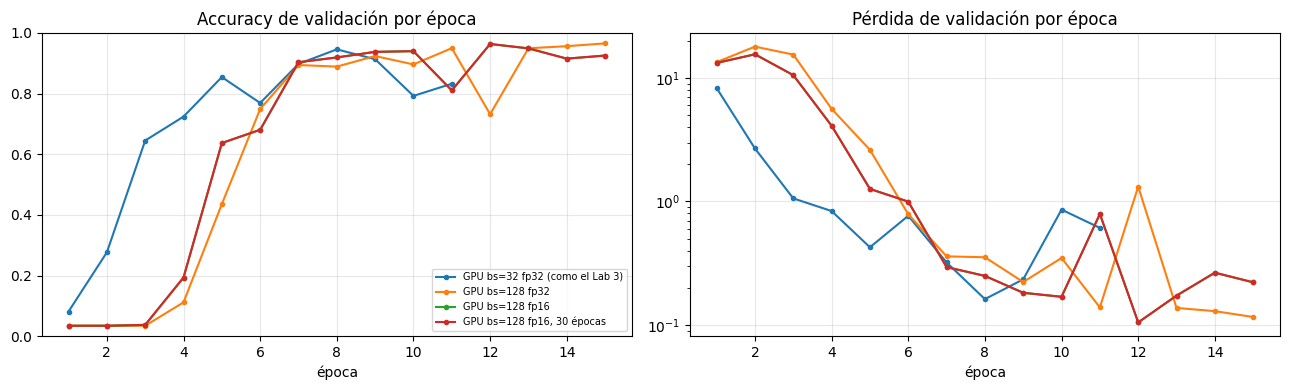

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, v in hist.items():
    ax[0].plot(range(1, len(v["val_accuracy"]) + 1), v["val_accuracy"], marker=".", label=k)
    ax[1].plot(range(1, len(v["val_loss"]) + 1), v["val_loss"], marker=".", label=k)
ax[0].set(title="Accuracy de validación por época", xlabel="época", ylim=(0, 1)); ax[1].set(title="Pérdida de validación por época", xlabel="época", yscale="log")
ax[0].legend(fontsize=7); ax[0].grid(alpha=.3); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(RES / "complemento_convergencia.png", dpi=130); plt.show()

In [10]:
(RES / "hardware_complemento.txt").write_text(subprocess.run("nvidia-smi", capture_output=True, text=True).stdout)
zp = "resultados_complemento.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for p in RES.glob("complemento_*"): z.write(p)
    z.write(RES / "hardware_complemento.txt")
print("Listo →", zp)
try:
    from google.colab import files; files.download(zp)
except Exception: pass

Listo → resultados_complemento.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>